# Chapitre 12 - Cours 6 : analytique prédictive, biais et boucles de rétroaction

Tout au long du livre, on a jugé les systèmes de données sur des critères techniques :
fiabilité, scalabilité, maintenabilité. La dernière section du chapitre, *Doing the Right Thing*, prend du recul : beaucoup de jeux de
données décrivent des **personnes**, et les décisions automatisées qu'on en tire ont des
conséquences voulues et non voulues sur leur vie. Les ingénieurs qui construisent ces
systèmes en portent une part de responsabilité. Les codes de déontologie existent (celui
de l'ACM par exemple), mais ils sont rarement discutés et encore moins appliqués ; et
l'éthique n'est pas une liste de cases à cocher, plutôt une réflexion continue, menée
avec les personnes concernées.

Ce notebook couvre la partie *Predictive Analytics* (sous-sections *Bias and discrimination*, *Responsibility and accountability*, *Feedback loops*).
Le livre argumente sans chiffres ; on va rendre chaque argument **mesurable** sur des
modèles jouets entièrement synthétiques (aucune donnée réelle) : quand on simule, les
mécanismes deviennent difficiles à nier.

**Plan.**

1. Prédire pour décider : l'asymétrie des erreurs et la « prison algorithmique ».
2. Biais et discrimination : un modèle qui n'a jamais vu l'attribut protégé.
3. Responsabilité, recours et explication.
4. Boucles de rétroaction.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import ethics as et
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Prédire pour décider : l'asymétrie des erreurs et la « prison algorithmique » (section *Predictive Analytics*)

Prédire la météo ou la progression d'une épidémie n'engage personne en particulier.
Prédire si **telle personne** va récidiver, rembourser un prêt ou coûter cher à son
assureur, c'est autre chose : la prédiction devient une décision qui touche
directement une vie.

**Pourquoi les organisations disent « non » au moindre doute.** Pour un prêteur, un bon
client refusé est une occasion manquée (gain perdu $g$), un mauvais client accepté est
une perte $\ell$ bien plus lourde. S'il estime à $p$ la probabilité de défaut, accepter
rapporte en moyenne $(1-p)\,g - p\,\ell$ : il accepte si et seulement si
$p < g / (g + \ell)$. Avec $\ell = 10\,g$, le seuil tombe à **9 %** : il suffit d'une
probabilité de défaut de 10 % pour être refusé, alors que 9 personnes sur 10 dans cette
situation auraient remboursé. Le calcul est rationnel pour l'organisation ; il fait
porter le coût de l'incertitude aux personnes.

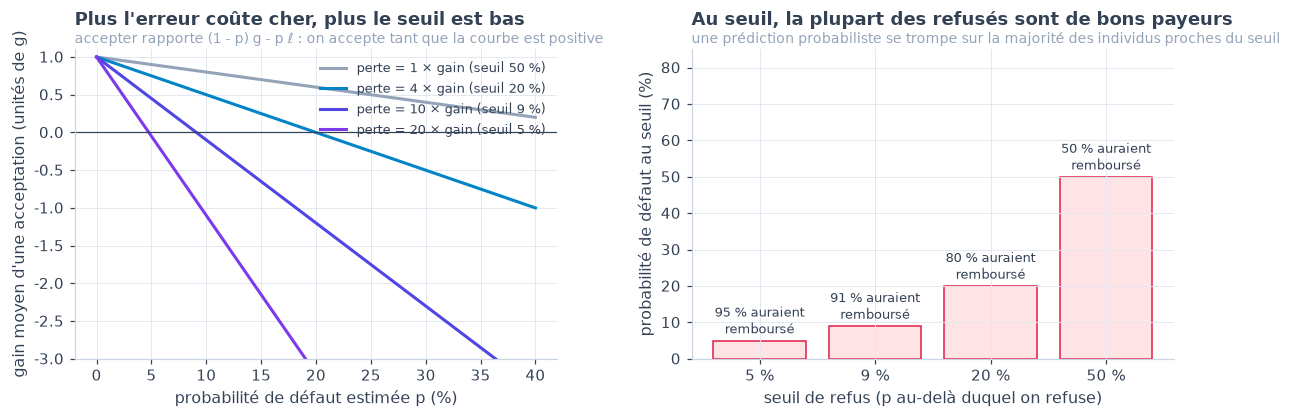

In [2]:
p = np.linspace(0, 0.4, 400)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
ax = axes[0]
for ratio, c in [(1, GRAY), (4, SKY), (10, INDIGO), (20, VIOLET)]:
    ax.plot(p * 100, (1 - p) - ratio * p, color=c, label=f"perte = {ratio} × gain (seuil {100 / (1 + ratio):.0f} %)")
ax.axhline(0, color=SLATE, lw=0.8)
ax.set_ylim(-3, 1.1)
ax.set_xlabel("probabilité de défaut estimée p (%)"); ax.set_ylabel("gain moyen d'une acceptation (unités de g)")
ax.set_title("Plus l'erreur coûte cher, plus le seuil est bas")
subtitle(ax, "accepter rapporte (1 - p) g - p ℓ : on accepte tant que la courbe est positive")
ax.legend(fontsize=8.5, loc="upper right")
ax = axes[1]
thr = np.array([0.05, 0.09, 0.2, 0.5])
ax.bar([f"{100 * t:.0f} %" for t in thr], [100 * t for t in thr], color=LIGHT[ROSE], edgecolor=ROSE,
       label="probabilité de défaut au seuil")
ax.set_ylabel("probabilité de défaut au seuil (%)"); ax.set_xlabel("seuil de refus (p au-delà duquel on refuse)")
for i, t in enumerate(thr):
    ax.text(i, 100 * t + 2, f"{100 - 100 * t:.0f} % auraient\nremboursé", ha="center", fontsize=8.5, color=SLATE)
ax.set_ylim(0, 85)
ax.set_title("Au seuil, la plupart des refusés sont de bons payeurs")
subtitle(ax, "une prédiction probabiliste se trompe sur la majorité des individus proches du seuil")
plt.tight_layout(); plt.show()

**De la décision isolée à l'exclusion systématique.** Un refus isolé est un désagrément.
Mais si les banques, les bailleurs, les assureurs, les employeurs et les compagnies
aériennes s'appuient sur **les mêmes données** (un même courtier, un même score), ils se
trompent sur **les mêmes personnes**. Être étiqueté « à risque », à tort ou à raison,
fait alors subir une avalanche de refus : on a parlé de **prison algorithmique**
(« algorithmic prison »). Là où la justice présume l'innocence et offre un appel, un
système automatisé peut exclure sans preuve et presque sans recours.

Simulons-le : 10 000 personnes, 10 organisations qui refusent chacune les 10 % de
dossiers jugés les plus risqués. Le score de chaque organisation est le risque réel plus
une erreur ; on fait varier la part $\rho$ de cette erreur qui est **commune** à toutes
(fonction `et.exclusion_counts`).

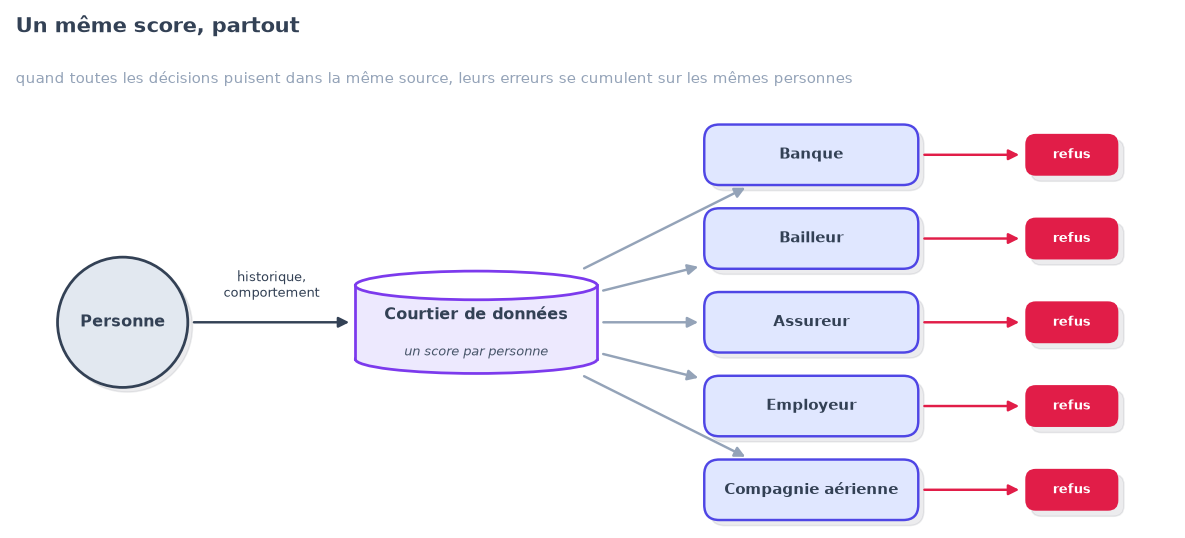

In [3]:
d = Diagram(12.5, 4.6, title="Un même score, partout",
            subtitle="quand toutes les décisions puisent dans la même source, leurs erreurs se cumulent sur les mêmes personnes")
d.box("p", 1.2, 2.2, "Personne", kind="user", w=1.4, color=SLATE)
d.box("cb", 5.0, 2.2, "Courtier de données", sub="un score par personne", color=VIOLET, kind="db", w=2.6, h=1.1)
orgs = ["Banque", "Bailleur", "Assureur", "Employeur", "Compagnie aérienne"]
for i, o in enumerate(orgs):
    y = 4.0 - i * 0.9
    d.box(f"o{i}", 8.6, y, o, color=INDIGO, w=2.3, h=0.65, fontsize=9.5)
    d.box(f"r{i}", 11.4, y, "refus", color=ROSE, kind="tag", w=1.0, h=0.45, fontsize=8.5)
    d.arrow("cb", f"o{i}", color=GRAY)
    d.arrow(f"o{i}", f"r{i}", color=ROSE)
d.arrow("p", "cb", "historique,\ncomportement", label_offset=(0, 0.4))
d.show()

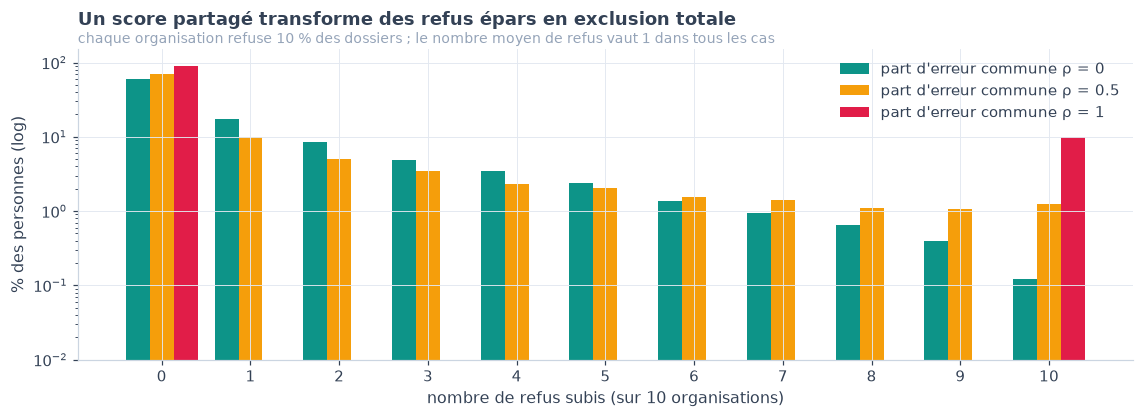

,jamais refusé (%),refusé 8 fois ou plus (%),dont risque réel sous la médiane (%)
ρ,,,
0.0,59.74,1.15,0.000
0.5,70.83,3.40,0.588
1.0,90.00,10.00,4.700


In [4]:
res = {}
for rho in (0.0, 0.5, 1.0):
    c, risk = et.exclusion_counts(n_people=10_000, n_orgs=10, reject_frac=0.1, rho=rho, seed=0)
    res[rho] = (c, risk)
fig, ax = plt.subplots(figsize=(10.5, 3.9))
w = 0.27
for j, (rho, col) in enumerate([(0.0, TEAL), (0.5, AMBER), (1.0, ROSE)]):
    c = res[rho][0]
    freq = np.bincount(c, minlength=11) / len(c) * 100
    ax.bar(np.arange(11) + (j - 1) * w, freq, width=w, color=col, label=f"part d'erreur commune ρ = {rho:g}")
ax.set_yscale("log"); ax.set_ylim(0.01, 150)
ax.set_xticks(range(11))
ax.set_xlabel("nombre de refus subis (sur 10 organisations)"); ax.set_ylabel("% des personnes (log)")
ax.set_title("Un score partagé transforme des refus épars en exclusion totale")
subtitle(ax, "chaque organisation refuse 10 % des dossiers ; le nombre moyen de refus vaut 1 dans tous les cas")
ax.legend()
plt.tight_layout(); plt.show()

rows = []
for rho, (c, risk) in res.items():
    prison = c >= 8
    rows.append({"ρ": rho, "jamais refusé (%)": (c == 0).mean() * 100,
                 "refusé 8 fois ou plus (%)": prison.mean() * 100,
                 "dont risque réel sous la médiane (%)": (risk[prison] < np.median(risk)).mean() * 100
                 if prison.any() else np.nan})
pd.DataFrame(rows).set_index("ρ")

Le nombre **moyen** de refus est le même dans les trois cas (une personne sur dix est
refusée par chaque organisation), mais sa **répartition** change tout. Avec des erreurs
indépendantes ($\rho = 0$), 60 % des gens ne sont jamais refusés et presque personne
n'est refusé partout : un refus est rattrapé ailleurs. Avec un score commun
($\rho = 1$), 10 % de la population est refusée par **les dix** organisations et 90 %
ne le sont jamais. Parmi ces exclus, environ 5 % ont pourtant un risque réel
**inférieur à la médiane** : 47 personnes sur 10 000, exclues de partout pour avoir été
mal notées une seule fois, par la seule source que tout le monde consulte. Avec des
erreurs indépendantes, aucune personne sous la médiane n'atteint 8 refus.

> **À retenir.** Une organisation prudente refuse au moindre doute, parce qu'une erreur
> lui coûte plus qu'une occasion manquée. Quand toutes les décisions puisent dans la
> même source, les erreurs ne se compensent plus : elles se concentrent sur les mêmes
> personnes, qui se retrouvent exclues de pans entiers de la société, sans preuve ni
> appel.

## 2. Biais et discrimination (sous-section *Bias and discrimination*)

Une décision prise par un algorithme n'est ni meilleure ni pire par nature que celle
d'un humain ; les humains ont leurs biais, et l'on espère parfois que les données
rendront les décisions plus justes. Mais un système d'apprentissage ne se contente pas
d'automatiser des règles écrites : il **infère les règles** à partir des données passées,
et ces règles sont opaques. Si les données portent un biais systématique, le modèle
l'apprend et le reproduit, voire l'amplifie.

Les lois anti-discrimination interdisent de traiter différemment selon des **attributs
protégés** (origine, âge, genre, handicap, convictions...). La parade naïve consiste à
retirer ces colonnes du modèle. Le livre montre pourquoi elle échoue : d'autres
variables sont **corrélées** à l'attribut protégé ; dans des quartiers ségrégués, le code
postal (ou même l'adresse IP) prédit très bien l'origine.

**Le laboratoire.** `et.make_credit_population` génère 20 000 demandeurs de crédit :

- deux groupes A (70 %) et B (30 %), avec **exactement la même** capacité réelle de
  remboursement ;
- 20 quartiers ; 85 % des membres de B habitent les quartiers 0 à 4, 85 % des membres
  de A les quartiers 5 à 19 ;
- un revenu et un taux d'endettement observés, bruités ;
- une étiquette **historique** « a remboursé » : pour B, un quart des bons payeurs ont
  été enregistrés comme mauvais payeurs (refus passés, recouvrements plus agressifs,
  historique incomplet). C'est le biais des données, pas celui des personnes.

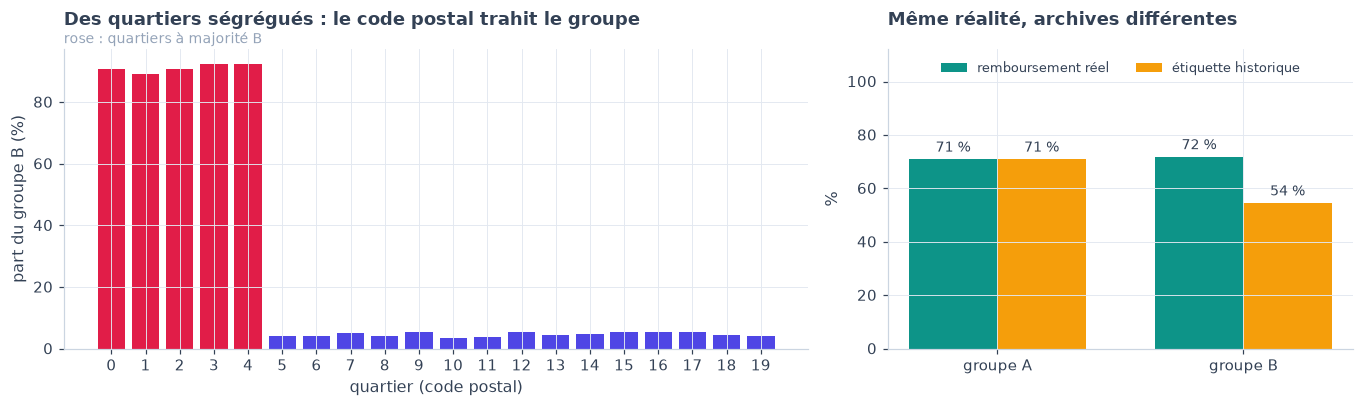

In [5]:
df = et.make_credit_population(n=20_000, seed=0)
by_zip = df.groupby("zip").agg(part_B=("group", "mean"), effectif=("group", "size"),
                               rembourse=("repaid", "mean"), etiquette=("label", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.bar(by_zip.index, by_zip["part_B"] * 100, color=[ROSE if v > 0.5 else INDIGO for v in by_zip["part_B"]])
ax.set_xticks(by_zip.index)
ax.set_xlabel("quartier (code postal)"); ax.set_ylabel("part du groupe B (%)")
ax.set_title("Des quartiers ségrégués : le code postal trahit le groupe")
subtitle(ax, "rose : quartiers à majorité B")
ax = axes[1]
tab = df.groupby("group")[["repaid", "label"]].mean() * 100
x = np.arange(2)
ax.bar(x - 0.18, tab["repaid"], 0.36, color=TEAL, label="remboursement réel")
ax.bar(x + 0.18, tab["label"], 0.36, color=AMBER, label="étiquette historique")
annotate_bars(ax, "{:.0f} %")
ax.set_xticks(x, ["groupe A", "groupe B"]); ax.set_ylim(0, 112); ax.set_ylabel("%")
ax.set_title("Même réalité, archives différentes")
ax.legend(loc="upper center", ncol=2, fontsize=8.5)
plt.tight_layout(); plt.show()

On entraîne trois régressions logistiques (implémentées en numpy par la méthode de
Newton, `et.fit_logistic`) sur l'étiquette historique, comme le ferait une équipe qui
« apprend des données » :

1. **avec** l'attribut de groupe (illégal) ;
2. **sans** le groupe, mais avec le quartier (« on ne regarde pas l'origine ») ;
3. avec seulement le revenu et l'endettement.

La banque accepte les 70 % de dossiers les mieux notés. On évalue ensuite chaque modèle
sur la **réalité** (remboursement réel), ce que la banque, elle, ne peut pas faire.

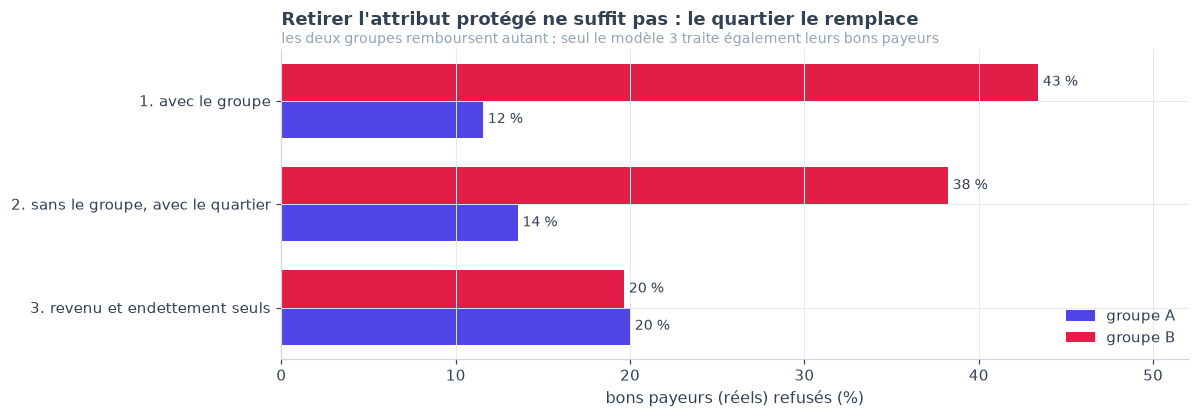

,acceptation A (%),acceptation B (%),ratio B / A,bons payeurs refusés A (%),bons payeurs refusés B (%)
1. avec le groupe,79.648,46.658,0.586,11.576,43.409
"2. sans le groupe, avec le quartier",77.514,51.821,0.669,13.562,38.236
3. revenu et endettement seuls,69.656,70.833,1.017,20.008,19.666


In [6]:
variants = {"1. avec le groupe": dict(use_group=True, use_zip=True),
            "2. sans le groupe, avec le quartier": dict(use_group=False, use_zip=True),
            "3. revenu et endettement seuls": dict(use_group=False, use_zip=False)}
y_true, y_hist, grp = df["repaid"].to_numpy(), df["label"].to_numpy(), df["group"].to_numpy()
scores, weights, tables = {}, {}, {}
for name, kw in variants.items():
    X = et.design_matrix(df, **kw)
    w_ = et.fit_logistic(X, y_hist)
    s = et.predict_proba(X, w_)
    scores[name], weights[name] = s, w_
    tables[name] = et.group_metrics(y_true, s, grp, threshold=np.quantile(s, 0.3))
summary = pd.DataFrame({name: {"acceptation A (%)": t.loc["A", "taux d'acceptation"] * 100,
                               "acceptation B (%)": t.loc["B", "taux d'acceptation"] * 100,
                               "ratio B / A": t.loc["B", "taux d'acceptation"] / t.loc["A", "taux d'acceptation"],
                               "bons payeurs refusés A (%)": t.loc["A", "bons payeurs refusés"] * 100,
                               "bons payeurs refusés B (%)": t.loc["B", "bons payeurs refusés"] * 100}
                        for name, t in tables.items()}).T
fig, ax = plt.subplots(figsize=(11, 3.9))
yy = np.arange(3)
ax.barh(yy + 0.18, summary["bons payeurs refusés A (%)"], 0.36, color=INDIGO, label="groupe A")
ax.barh(yy - 0.18, summary["bons payeurs refusés B (%)"], 0.36, color=ROSE, label="groupe B")
annotate_bars(ax, "{:.0f} %")
ax.set_yticks(yy, summary.index); ax.invert_yaxis()
ax.set_xlabel("bons payeurs (réels) refusés (%)"); ax.set_xlim(0, 52)
ax.set_title("Retirer l'attribut protégé ne suffit pas : le quartier le remplace")
subtitle(ax, "les deux groupes remboursent autant ; seul le modèle 3 traite également leurs bons payeurs")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
summary

Le modèle 1 refuse 43 % des bons payeurs de B contre 12 % de ceux de A : il a appris le
biais des archives, et l'attribut de groupe lui a servi à l'appliquer. Le modèle 2 n'a
**jamais vu** le groupe, et pourtant il refuse encore 38 % des bons payeurs de B : le
quartier sert de **variable proxy**. Son ratio d'acceptation B / A (environ 0,67) est
sous le seuil de 0,8 que la doctrine américaine de l'« impact disproportionné » (règle
des quatre cinquièmes) considère comme un signal d'alerte. Seul le modèle 3, privé du
proxy, traite les deux groupes à peu près également, au prix d'un peu moins de
finesse. Encore faut-il que les variables restantes ne soient pas elles-mêmes
corrélées au groupe ; ici on l'a garanti par construction, dans la réalité on ne le
sait jamais vraiment.

Regardons ce que le modèle 2 a appris : le coefficient de chaque quartier (par rapport
au quartier 0).

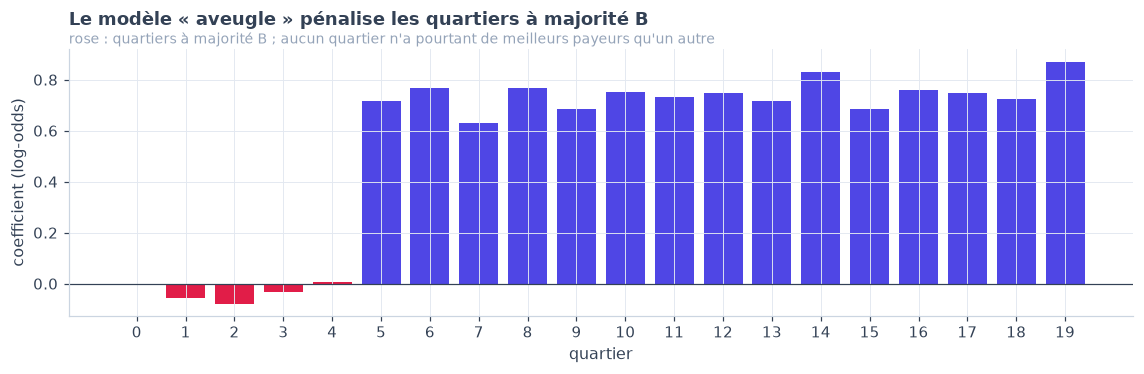

In [7]:
w2 = weights["2. sans le groupe, avec le quartier"]
coef_zip = np.r_[0.0, w2[3:]]
fig, ax = plt.subplots(figsize=(10.5, 3.5))
ax.bar(range(20), coef_zip, color=[ROSE if v > 0.5 else INDIGO for v in by_zip["part_B"]])
ax.axhline(0, color=SLATE, lw=0.8)
ax.set_xticks(range(20)); ax.set_xlabel("quartier"); ax.set_ylabel("coefficient (log-odds)")
ax.set_title("Le modèle « aveugle » pénalise les quartiers à majorité B")
subtitle(ax, "rose : quartiers à majorité B ; aucun quartier n'a pourtant de meilleurs payeurs qu'un autre")
plt.tight_layout(); plt.show()

**Calibré sur le passé, faux sur la réalité.** Un critère d'équité souvent mis en avant
est la **calibration** : parmi les personnes notées 70 %, 70 % remboursent, quel que
soit leur groupe. Mesurons la calibration du modèle 2 deux fois : contre les étiquettes
historiques (ce que voit l'équipe qui valide le modèle) et contre la réalité.

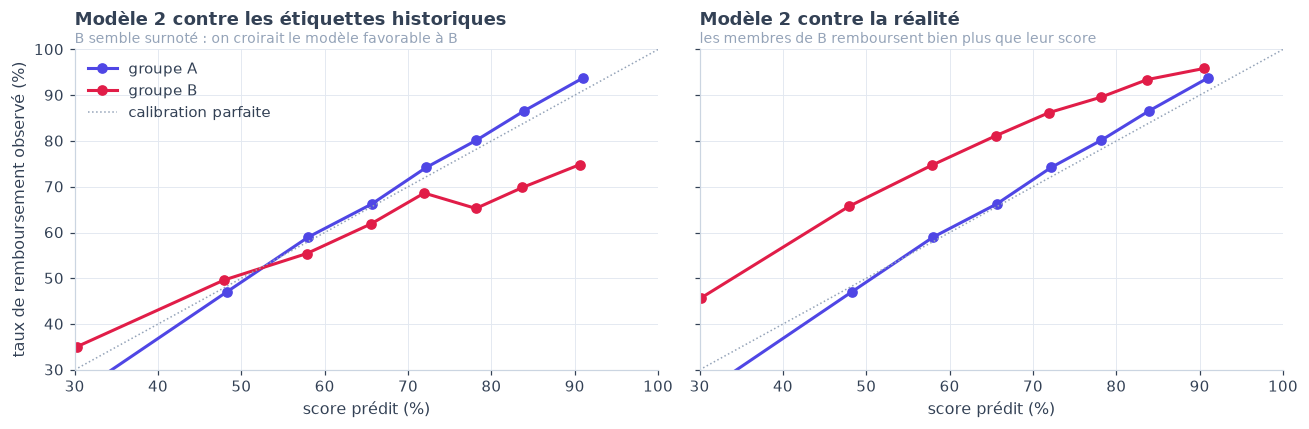

In [8]:
s2 = scores["2. sans le groupe, avec le quartier"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, y_, ttl in [(axes[0], y_hist, "contre les étiquettes historiques"), (axes[1], y_true, "contre la réalité")]:
    cal = et.calibration_table(y_, s2, grp, bins=8)
    for gname, col in [("A", INDIGO), ("B", ROSE)]:
        c = cal[cal["groupe"] == gname]
        ax.plot(c["score moyen"] * 100, c["taux observé"] * 100, "o-", color=col, label=f"groupe {gname}")
    ax.plot([30, 100], [30, 100], color=GRAY, ls=":", lw=1, label="calibration parfaite")
    ax.set_xlabel("score prédit (%)"); ax.set_title(f"Modèle 2 {ttl}")
    ax.set_xlim(30, 100); ax.set_ylim(30, 100)
axes[0].set_ylabel("taux de remboursement observé (%)")
axes[0].legend(loc="upper left")
subtitle(axes[0], "B semble surnoté : on croirait le modèle favorable à B")
subtitle(axes[1], "les membres de B remboursent bien plus que leur score")
plt.tight_layout(); plt.show()

Contre les archives, le modèle est bien calibré pour A, et il **surestime** B : à score
égal, les membres de B ont moins souvent l'étiquette « a remboursé ». Une équipe qui
valide le modèle sur les données disponibles conclurait qu'il est plutôt favorable à B,
voire qu'il faudrait le durcir. Contre la réalité, c'est l'inverse : à score égal, les
membres de B remboursent nettement **plus** que ceux de A, de 10 à 18 points. Le modèle
est fidèle à des données injustes, et une validation, aussi rigoureuse soit-elle, ne
peut pas détecter un biais que partagent toutes les données disponibles ; elle peut
même pousser à l'aggraver.

On comprend la boutade citée par le livre : l'apprentissage automatique serait au biais
ce que le blanchiment est à l'argent sale. On entre des décisions passées
discriminatoires, on obtient un score d'apparence objective. Les systèmes prédictifs
**extrapolent le passé** ; si le passé est discriminatoire, ils codifient la
discrimination. Vouloir un avenir meilleur que le passé demande de l'**imagination
morale**, et cela, seuls des humains peuvent l'apporter.

> **À retenir.** Un modèle entraîné sur des décisions historiques apprend leurs biais.
> Retirer l'attribut protégé ne suffit pas, parce que des variables proxy (quartier,
> adresse IP...) le reconstruisent. Pire, la validation sur les données disponibles
> peut faire croire au biais inverse : le biais n'est visible que si l'on compare à une
> réalité que les données ne contiennent pas.